In [ ]:
from pathlib import Path
import json
import time
from datetime import datetime

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

PROJECT = Path(r"D:\Semester3\LLVM\Assignments\SemesterProject")
ROOT = PROJECT / "RadioMapSeer"
LABELS_DIR = PROJECT / "labels"
ARTIFACTS_DIR = PROJECT / "artifacts"
LABELS_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)

# frozen product settings
THR = 100
NUM_TX = 80
SEED = 42
GAIN_MODEL = "DPM"

# SMALL RUN (CPU-friendly). On GPU later: N_TRAIN=None for full, BATCH=8, EPOCHS=40, BASE_CH=32
N_TRAIN = 40
N_VAL = 10
N_TEST = 10
BATCH_SIZE = 2
NUM_WORKERS = 0
LR = 1e-3
EPOCHS = 3
BASE_CH = 16
EARLY_STOP_PATIENCE = 5
LOG_EVERY = 200

# ---------- frozen settings ----------
# THR = 100
# NUM_TX = 80
# SEED = 42
# GAIN_MODEL = "DPM"
# BATCH_SIZE = 8          # use 4 if GPU RAM is low; 2 on CPU
# NUM_WORKERS = 0         # Windows: keep 0
# LR = 1e-3
# EPOCHS = 20             # raise to 40–50 for stronger final model
# BASE_CH = 32

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
np.random.seed(SEED)

print("device:", device)
print("cuda:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("ROOT exists:", ROOT.exists())
assert ROOT.exists(), f"Missing dataset at {ROOT}"

device: cpu
cuda: CPU
ROOT exists: True


In [12]:
def load_gray(path: Path) -> np.ndarray:
    return np.array(Image.open(path).convert("L"), dtype=np.float32)

def load_antennas(map_id: int):
    with open(ROOT / "antenna" / f"{map_id}.json") as f:
        return json.load(f)

def building_path(map_id: int) -> Path:
    return ROOT / "png" / "buildings_complete" / f"{map_id}.png"

def gain_path(map_id: int, tx_id: int) -> Path:
    return ROOT / "gain" / GAIN_MODEL / f"{map_id}_{tx_id}.png"

def coverage_score(coverage_img, buildings_img, thr=THR) -> float:
    free = buildings_img < 128
    good = (coverage_img >= thr) & free
    return float(100.0 * good.sum() / max(int(free.sum()), 1))

def make_tx_channel(h, w, xy) -> np.ndarray:
    ch = np.zeros((h, w), dtype=np.float32)
    x, y = int(xy[0]), int(xy[1])
    if 0 <= x < w and 0 <= y < h:
        ch[y, x] = 1.0
    return ch

def list_map_ids():
    return sorted(int(p.stem) for p in (ROOT / "png" / "buildings_complete").glob("*.png"))

MAP_IDS = list_map_ids()
print(f"num maps={len(MAP_IDS)}  range={MAP_IDS[0]}..{MAP_IDS[-1]}")

num maps=701  range=0..700


In [13]:
b0 = load_gray(building_path(0))
s0 = np.array([coverage_score(load_gray(gain_path(0, t)), b0) for t in range(NUM_TX)])
print("map0 best TX", int(s0.argmax()), "score", round(float(s0.max()), 2))
print("expected ~ TX 43 @ ~55.6%")

map0 best TX 43 score 55.62
expected ~ TX 43 @ ~55.6%


In [14]:
scores_path = LABELS_DIR / "scores.npy"
splits_path = LABELS_DIR / "splits.json"
meta_path = LABELS_DIR / "meta.json"
FORCE_REBUILD = False

if scores_path.exists() and splits_path.exists() and not FORCE_REBUILD:
    print("Labels already exist — skip rebuild.")
else:
    max_id = max(MAP_IDS)
    scores = np.full((max_id + 1, NUM_TX), np.nan, dtype=np.float32)
    t0 = time.time()
    for i, m in enumerate(MAP_IDS):
        buildings = load_gray(building_path(m))
        for t in range(NUM_TX):
            scores[m, t] = coverage_score(load_gray(gain_path(m, t)), buildings)
        if (i + 1) % 10 == 0 or (i + 1) == len(MAP_IDS):
            elapsed = time.time() - t0
            rate = (i + 1) / max(elapsed, 1e-6)
            eta = (len(MAP_IDS) - i - 1) / max(rate, 1e-6)
            print(f"[{i+1}/{len(MAP_IDS)}] map={m} ETA~{eta/60:.1f} min")
    np.save(scores_path, scores)

    rng = np.random.default_rng(SEED)
    perm = rng.permutation(MAP_IDS)
    n = len(perm)
    n_train = int(0.8 * n)
    n_val = int(0.1 * n)
    splits = {
        "train": sorted(perm[:n_train].tolist()),
        "val": sorted(perm[n_train:n_train + n_val].tolist()),
        "test": sorted(perm[n_train + n_val:].tolist()),
    }
    with open(splits_path, "w") as f:
        json.dump(splits, f, indent=2)
    with open(meta_path, "w") as f:
        json.dump(
            {"thr": THR, "num_tx": NUM_TX, "gain_model": GAIN_MODEL,
             "n_maps": len(MAP_IDS), "seed": SEED,
             "created_at": datetime.utcnow().isoformat() + "Z"},
            f, indent=2,
        )
    print("saved", scores_path, "splits", {k: len(v) for k, v in splits.items()})

Labels already exist — skip rebuild.


In [15]:
scores = np.load(LABELS_DIR / "scores.npy")
with open(LABELS_DIR / "splits.json") as f:
    splits = json.load(f)

train_maps_full = splits["train"]
val_maps_full = splits["val"]
test_maps_full = splits["test"]

train_maps = train_maps_full[:N_TRAIN]
val_maps = val_maps_full[:N_VAL]
test_maps = test_maps_full[:N_TEST]

print("FULL splits:", len(train_maps_full), len(val_maps_full), len(test_maps_full))
print("SMALL run:", len(train_maps), len(val_maps), len(test_maps))
print("map0 best", int(np.nanargmax(scores[0])), float(np.nanmax(scores[0])))

FULL splits: 560 70 71
SMALL run: 40 10 10
map0 best 43 55.616851806640625


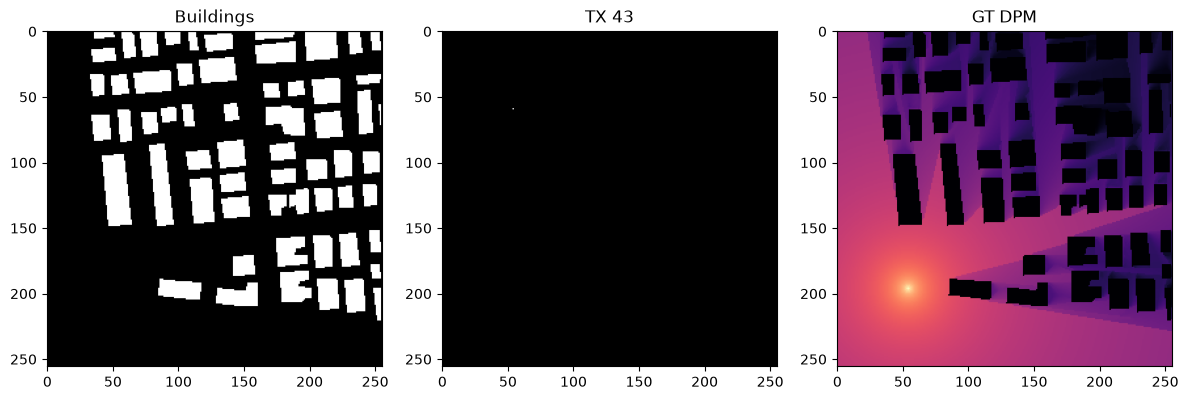

In [16]:
mid, tid = 0, int(np.nanargmax(scores[0]))
buildings = load_gray(building_path(mid))
txs = load_antennas(mid)
gain = load_gray(gain_path(mid, tid))
tx_ch = make_tx_channel(*buildings.shape, txs[tid])

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(buildings, cmap="gray"); ax[0].set_title("Buildings")
ax[1].imshow(tx_ch, cmap="gray"); ax[1].set_title(f"TX {tid}")
ax[2].imshow(gain, cmap="magma"); ax[2].set_title("GT DPM")
plt.tight_layout(); plt.show()

In [17]:
class CoveragePairDataset(Dataset):
    def __init__(self, map_ids):
        self.samples = [(int(m), t) for m in map_ids for t in range(NUM_TX)]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        map_id, tx_id = self.samples[idx]
        buildings = load_gray(building_path(map_id)) / 255.0
        gain = load_gray(gain_path(map_id, tx_id)) / 255.0
        txs = load_antennas(map_id)
        tx_ch = make_tx_channel(*buildings.shape, txs[tx_id])
        x = np.stack([buildings, tx_ch], axis=0)
        y = gain[None, ...]
        return torch.from_numpy(x), torch.from_numpy(y)

train_ds = CoveragePairDataset(train_maps)
val_ds = CoveragePairDataset(val_maps)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"train pairs={len(train_ds)}  val pairs={len(val_ds)}")
print(f"steps/epoch≈{len(train_loader)}  (expect ~{N_TRAIN*NUM_TX // BATCH_SIZE})")

train pairs=3200  val pairs=800
steps/epoch≈1600  (expect ~1600)


In [18]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class CoverageUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.enc1 = DoubleConv(2, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out_conv = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.sigmoid(self.out_conv(d1))

model = CoverageUNet(base=BASE_CH).to(device)
print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M | BASE_CH={BASE_CH}")

params: 0.48M | BASE_CH=16


C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\4069849791.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\4069849791.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Training 5 epochs | device=cpu | train pairs=3200
epoch 01/5  train=0.0865  val=0.0797  <-- saved best
epoch 02/5  train=0.0704  val=0.0836
epoch 03/5  train=0.0691  val=0.0789  <-- saved best
epoch 04/5  train=0.0682  val=0.0801
epoch 05/5  train=0.0674  val=0.0749  <-- saved best
done in 28.1 min | best val L1=0.0749
checkpoint: D:\Semester3\LLVM\Assignments\SemesterProject\artifacts\unet_best.pt


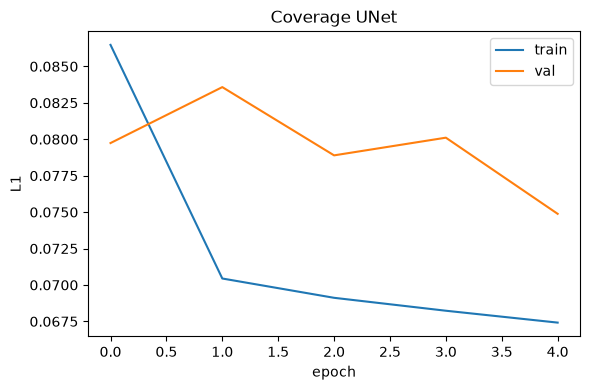

In [19]:
EPOCHS = 5 if device.type == "cpu" else 40
EARLY_STOP_PATIENCE = 8

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.L1Loss()
use_amp = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

history = {"train": [], "val": []}
best_val = float("inf")
best_path = ARTIFACTS_DIR / "unet_best.pt"
patience = 0

def run_epoch(loader, train_mode: bool):
    model.train(train_mode)
    total, n = 0.0, 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        with torch.set_grad_enabled(train_mode):
            with torch.cuda.amp.autocast(enabled=use_amp):
                pred = model(x)
                loss = criterion(pred, y)
            if train_mode:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total += loss.item() * x.size(0)
        n += x.size(0)
    return total / max(n, 1)

print(f"Training {EPOCHS} epochs | device={device} | train pairs={len(train_ds)}")
t_train = time.time()

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    history["train"].append(tr)
    history["val"].append(va)

    marker = ""
    if va < best_val:
        best_val = va
        patience = 0
        torch.save(
            {
                "model": model.state_dict(),
                "epoch": epoch,
                "val_l1": va,
                "config": {"thr": THR, "base": BASE_CH, "gain_model": GAIN_MODEL, "seed": SEED},
            },
            best_path,
        )
        marker = "  <-- saved best"
    else:
        patience += 1

    print(f"epoch {epoch:02d}/{EPOCHS}  train={tr:.4f}  val={va:.4f}{marker}")
    if patience >= EARLY_STOP_PATIENCE:
        print("early stop")
        break

print(f"done in {(time.time()-t_train)/60:.1f} min | best val L1={best_val:.4f}")
print("checkpoint:", best_path)

plt.figure(figsize=(6, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("L1"); plt.legend(); plt.title("Coverage UNet")
plt.tight_layout(); plt.show()

C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\4285927696.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\4285927696.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


SMALL train | epochs=5 | device=cpu | pairs=3200
  step 200/1600  loss=0.0658
  step 400/1600  loss=0.0606
  step 600/1600  loss=0.0520
  step 800/1600  loss=0.0690
  step 1000/1600  loss=0.0563
  step 1200/1600  loss=0.0637
  step 1400/1600  loss=0.0575
  step 1600/1600  loss=0.0724
epoch 01/5  train=0.0665  val=0.0741  <-- saved best
  step 200/1600  loss=0.0620
  step 400/1600  loss=0.0600
  step 600/1600  loss=0.0678
  step 800/1600  loss=0.0593
  step 1000/1600  loss=0.0554
  step 1200/1600  loss=0.0652
  step 1400/1600  loss=0.0756
  step 1600/1600  loss=0.0662
epoch 02/5  train=0.0660  val=0.0760
  step 200/1600  loss=0.0689
  step 400/1600  loss=0.0571
  step 600/1600  loss=0.0630
  step 800/1600  loss=0.0608
  step 1000/1600  loss=0.0601
  step 1200/1600  loss=0.0633
  step 1400/1600  loss=0.0534
  step 1600/1600  loss=0.0520
epoch 03/5  train=0.0655  val=0.0773
  step 200/1600  loss=0.0707
  step 400/1600  loss=0.0576
  step 600/1600  loss=0.0517
  step 800/1600  loss=0.0750


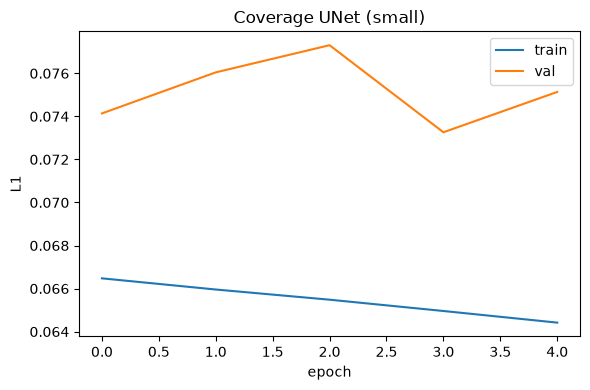

In [20]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.L1Loss()
use_amp = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

history = {"train": [], "val": []}
best_val = float("inf")
best_path = ARTIFACTS_DIR / "unet_best_small.pt"
patience = 0

def run_epoch(loader, train_mode: bool):
    model.train(train_mode)
    total, n = 0.0, 0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(train_mode):
            with torch.cuda.amp.autocast(enabled=use_amp):
                pred = model(x)
                loss = criterion(pred, y)
            if train_mode:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total += loss.item() * x.size(0)
        n += x.size(0)
        if train_mode and step % LOG_EVERY == 0:
            print(f"  step {step}/{len(loader)}  loss={loss.item():.4f}")
    return total / max(n, 1)

print(f"SMALL train | epochs={EPOCHS} | device={device} | pairs={len(train_ds)}")
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    history["train"].append(tr)
    history["val"].append(va)

    marker = ""
    if va < best_val:
        best_val = va
        patience = 0
        torch.save(
            {
                "model": model.state_dict(),
                "epoch": epoch,
                "val_l1": va,
                "config": {
                    "thr": THR, "base": BASE_CH, "gain_model": GAIN_MODEL,
                    "seed": SEED, "n_train_maps": len(train_maps), "small_run": True,
                },
            },
            best_path,
        )
        marker = "  <-- saved best"
    else:
        patience += 1

    print(f"epoch {epoch:02d}/{EPOCHS}  train={tr:.4f}  val={va:.4f}{marker}")
    if patience >= EARLY_STOP_PATIENCE:
        print("early stop")
        break

print(f"done in {(time.time()-t0)/60:.1f} min | best val L1={best_val:.4f}")
print("checkpoint:", best_path)

plt.figure(figsize=(6, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("L1"); plt.legend(); plt.title("Coverage UNet (small)")
plt.tight_layout(); plt.show()

In [21]:
ckpt = torch.load(ARTIFACTS_DIR / "unet_best_small.pt", map_location=device)
model.load_state_dict(ckpt["model"])
model.eval()
print("loaded epoch", ckpt["epoch"], "val_l1", ckpt["val_l1"])

@torch.no_grad()
def predict_coverage(map_id: int, tx_id: int) -> np.ndarray:
    buildings = load_gray(building_path(map_id)) / 255.0
    txs = load_antennas(map_id)
    tx_ch = make_tx_channel(*buildings.shape, txs[tx_id])
    x = torch.from_numpy(np.stack([buildings, tx_ch], 0)[None, ...]).to(device)
    with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
        pred = model(x)
    return pred.float().cpu().numpy()[0, 0] * 255.0

loaded epoch 4 val_l1 0.0732619315199554


C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\3396950666.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


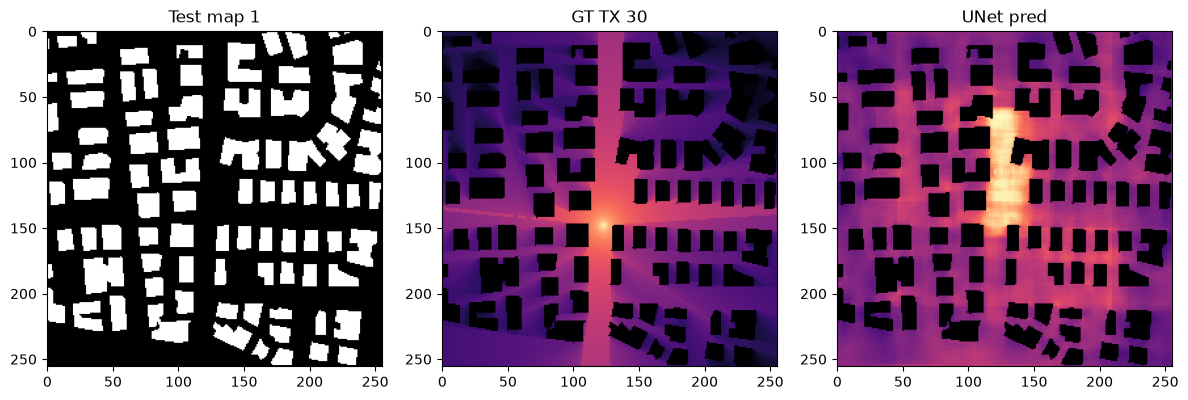

RMSE: 27.87


In [22]:
map_id = test_maps[0]
tx_id = int(np.nanargmax(scores[map_id]))
gt = load_gray(gain_path(map_id, tx_id))
pred = predict_coverage(map_id, tx_id)
buildings = load_gray(building_path(map_id))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(buildings, cmap="gray"); ax[0].set_title(f"Test map {map_id}")
ax[1].imshow(gt, cmap="magma"); ax[1].set_title(f"GT TX {tx_id}")
ax[2].imshow(pred, cmap="magma"); ax[2].set_title("UNet pred")
plt.tight_layout(); plt.show()
print("RMSE:", round(float(np.sqrt(np.mean((pred - gt) ** 2))), 2))

In [23]:
@torch.no_grad()
def rank_map(map_id: int):
    buildings = load_gray(building_path(map_id))
    pred_scores = np.zeros(NUM_TX, dtype=np.float32)
    for t in range(NUM_TX):
        pred_scores[t] = coverage_score(predict_coverage(map_id, t), buildings)
    return pred_scores, np.argsort(-pred_scores)

def center_tx(map_id: int) -> int:
    txs = load_antennas(map_id)
    return min(range(NUM_TX), key=lambda i: (txs[i][0]-128)**2 + (txs[i][1]-128)**2)

map_id = test_maps[0]
gt = scores[map_id]
_, order = rank_map(map_id)

def row(name, tid):
    s = float(gt[tid])
    rank = 1 + int(np.sum(gt > s))
    pct = 100.0 * s / float(np.nanmax(gt))
    print(f"{name:12s} TX={tid:2d}  score={s:5.2f}%  rank={rank:2d}/80  %opt={pct:5.1f}")

print(f"=== map {map_id} ===")
row("Oracle", int(np.nanargmax(gt)))
row("UNet", int(order[0]))
row("Center", center_tx(map_id))
row("Random", int(np.random.default_rng(0).integers(0, NUM_TX)))
print("UNet top5", order[:5].tolist())
print("GT top5  ", np.argsort(-gt)[:5].tolist())

C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\3396950666.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


=== map 1 ===
Oracle       TX=30  score=26.46%  rank= 1/80  %opt=100.0
UNet         TX=30  score=26.46%  rank= 1/80  %opt=100.0
Center       TX=69  score=23.66%  rank= 5/80  %opt= 89.4
Random       TX=68  score=23.52%  rank= 6/80  %opt= 88.9
UNet top5 [30, 54, 0, 27, 73]
GT top5   [30, 42, 74, 43, 69]


In [24]:
def eval_test_maps(map_list):
    rows = []
    for i, m in enumerate(map_list):
        gt = scores[m]
        _, order = rank_map(m)
        for method, tid in [
            ("oracle", int(np.nanargmax(gt))),
            ("unet", int(order[0])),
            ("center", center_tx(m)),
            ("random", int(np.random.default_rng(m).integers(0, NUM_TX))),
        ]:
            s = float(gt[tid])
            rows.append({
                "map": m, "method": method, "tx": tid, "score": s,
                "rank": 1 + int(np.sum(gt > s)),
                "pct_opt": 100.0 * s / float(np.nanmax(gt)),
            })
        print(f"[{i+1}/{len(map_list)}] map {m}: unet TX {int(order[0])}")

    for method in ["oracle", "unet", "center", "random"]:
        sub = [r for r in rows if r["method"] == method]
        print(
            f"{method:8s} mean_score={np.mean([r['score'] for r in sub]):5.2f} "
            f"mean_rank={np.mean([r['rank'] for r in sub]):5.1f} "
            f"mean_%opt={np.mean([r['pct_opt'] for r in sub]):5.1f}"
        )
    out = LABELS_DIR / "eval_test_ranking_small.json"
    with open(out, "w") as f:
        json.dump(rows, f, indent=2)
    print("wrote", out)

eval_test_maps(test_maps)

C:\Users\swapn\AppData\Local\Temp\ipykernel_14928\3396950666.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


[1/10] map 1: unet TX 30
[2/10] map 10: unet TX 2
[3/10] map 15: unet TX 19
[4/10] map 34: unet TX 35
[5/10] map 41: unet TX 39
[6/10] map 42: unet TX 24
[7/10] map 49: unet TX 59
[8/10] map 57: unet TX 43
[9/10] map 63: unet TX 28
[10/10] map 69: unet TX 31
oracle   mean_score=30.31 mean_rank=  1.0 mean_%opt=100.0
unet     mean_score=20.32 mean_rank= 30.2 mean_%opt= 68.9
center   mean_score=20.30 mean_rank= 33.3 mean_%opt= 67.3
random   mean_score=19.55 mean_rank= 34.6 mean_%opt= 65.2
wrote D:\Semester3\LLVM\Assignments\SemesterProject\labels\eval_test_ranking_small.json
